# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


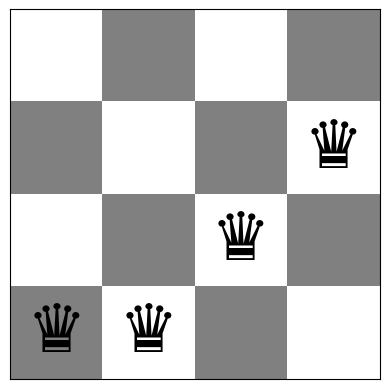

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


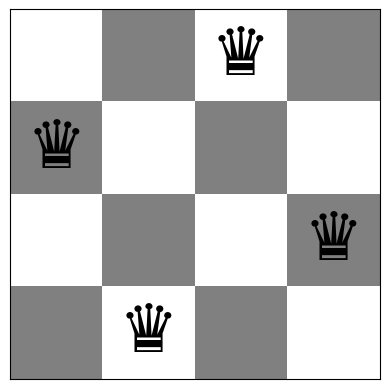

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Steepest-ascent HC: h=2, steps=2, objective evaluations=169, time=0.001175s, status=local optimum
Board with 2 conflicts.


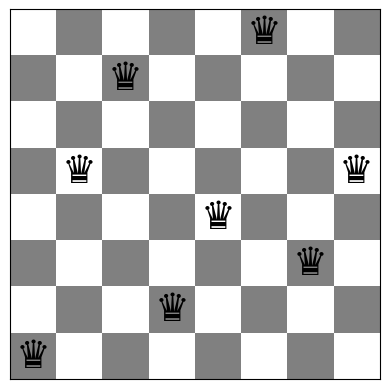

In [5]:
# Task 1: Steepest-ascent Hill Climbing
# The helpers below are shared by later tasks. They keep one queen in each column.
import time
import math
from IPython.display import display, Markdown


def _make_random_neighbor(board, move_operator="standard"):
    """Return one random neighbor using the selected local-move operator."""
    q = np.asarray(board, dtype=int).copy()
    n = len(q)
    if n < 2:
        return q

    def different_row(old_row):
        # Uniformly select any row except the queen's current row.
        row = np.random.randint(0, n - 1)
        if row >= old_row:
            row += 1
        return row

    if move_operator == "standard":
        col = np.random.randint(n)
        q[col] = different_row(int(q[col]))

    elif move_operator == "single_step":
        col = np.random.randint(n)
        possible_rows = [r for r in (int(q[col]) - 1, int(q[col]) + 1) if 0 <= r < n]
        if possible_rows:
            q[col] = int(np.random.choice(possible_rows))

    elif move_operator == "column_swap":
        c1, c2 = np.random.choice(n, size=2, replace=False)
        q[c1], q[c2] = q[c2], q[c1]

    elif move_operator == "dual_queen":
        c1, c2 = np.random.choice(n, size=2, replace=False)
        q[c1] = different_row(int(q[c1]))
        q[c2] = different_row(int(q[c2]))

    elif move_operator == "adaptive":
        # Count the conflicts contributed by each queen and focus on a most-conflicted queen.
        queen_conflicts = np.zeros(n, dtype=int)
        for i in range(n):
            for j in range(i + 1, n):
                if q[i] == q[j] or abs(int(q[i]) - int(q[j])) == abs(i - j):
                    queen_conflicts[i] += 1
                    queen_conflicts[j] += 1
        candidates = np.flatnonzero(queen_conflicts == queen_conflicts.max())
        col = int(np.random.choice(candidates))
        q[col] = different_row(int(q[col]))

    else:
        raise ValueError(f"Unknown move operator: {move_operator}")
    return q


def _neighbor_count(n, move_operator="standard"):
    """Estimate the size of a local-neighbor set for a stopping rule."""
    n = int(n)
    if move_operator == "single_step":
        return max(1, 2 * n)
    if move_operator == "column_swap":
        return max(1, n * (n - 1) // 2)
    if move_operator == "dual_queen":
        return max(1, n * (n - 1) // 2 * (n - 1) ** 2)
    return max(1, n * (n - 1))


def _pack_result(board, best_conflicts, steps, evaluations, history, trace,
                 start_time, reason, iterations=None):
    """Use a common result format for comparison and plotting."""
    elapsed = time.perf_counter() - start_time
    return {
        "board": np.asarray(board, dtype=int).copy(),
        "conflicts": int(best_conflicts),
        "steps": int(steps),
        "iterations": int(len(trace) - 1 if iterations is None else iterations),
        "evaluations": int(evaluations),
        "history": [int(x) for x in history],  # best-so-far objective values
        "trace": [int(x) for x in trace],      # state objective after each iteration/trial
        "success": bool(best_conflicts == 0),
        "runtime": float(elapsed),
        "reason": reason,
    }


def steepest_hill_climbing(board):
    """Evaluate every single-queen move and accept the best strict improvement."""
    start_time = time.perf_counter()
    current = np.asarray(board, dtype=int).copy()
    current_value = int(conflicts(current))
    evaluations = 1
    steps = 0
    history = [current_value]
    trace = [current_value]
    reason = "local optimum"
    n = len(current)

    while current_value > 0:
        best_value = current_value
        best_moves = []
        # There are n * (n - 1) legal single-queen row changes.
        for col in range(n):
            for row in range(n):
                if row == current[col]:
                    continue
                candidate = current.copy()
                candidate[col] = row
                value = int(conflicts(candidate))
                evaluations += 1
                if value < best_value:
                    best_value = value
                    best_moves = [(candidate, value)]
                elif value == best_value and value < current_value:
                    best_moves.append((candidate, value))

        if not best_moves:
            trace.append(current_value)
            break

        # Random tie-breaking does not change the steepest-ascent rule.
        chosen = int(np.random.randint(len(best_moves)))
        current, current_value = best_moves[chosen]
        steps += 1
        history.append(current_value)
        trace.append(current_value)
        if current_value == 0:
            reason = "solution found"
            break

    if current_value == 0:
        reason = "solution found"
    return _pack_result(current, current_value, steps, evaluations, history, trace,
                        start_time, reason)


# Demonstration on a random 8-Queens board.
np.random.seed(101)
_demo_steepest = steepest_hill_climbing(random_board(8))
print(f"Steepest-ascent HC: h={_demo_steepest['conflicts']}, steps={_demo_steepest['steps']}, "
      f"objective evaluations={_demo_steepest['evaluations']}, time={_demo_steepest['runtime']:.6f}s, "
      f"status={_demo_steepest['reason']}")
show_board(_demo_steepest["board"], fontsize=28)

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
# Task 2: Inefficient Stochastic Hill Climbing
# At every step this method evaluates every legal single-queen move, then randomly selects
# one of the moves whose objective value is strictly better than the current state.

def inefficient_stochastic_hill_climbing(board):
    start_time = time.perf_counter()
    current = np.asarray(board, dtype=int).copy()
    current_value = int(conflicts(current))
    evaluations = 1
    steps = 0
    history = [current_value]
    trace = [current_value]
    reason = "local optimum"
    n = len(current)

    while current_value > 0:
        improving_moves = []
        for col in range(n):
            for row in range(n):
                if row == current[col]:
                    continue
                candidate = current.copy()
                candidate[col] = row
                value = int(conflicts(candidate))
                evaluations += 1
                if value < current_value:
                    improving_moves.append((candidate, value))

        if not improving_moves:
            trace.append(current_value)
            break

        chosen = int(np.random.randint(len(improving_moves)))
        current, current_value = improving_moves[chosen]
        steps += 1
        history.append(current_value)
        trace.append(current_value)
        if current_value == 0:
            reason = "solution found"
            break

    if current_value == 0:
        reason = "solution found"
    return _pack_result(current, current_value, steps, evaluations, history, trace,
                        start_time, reason)


np.random.seed(202)
_demo_inefficient = inefficient_stochastic_hill_climbing(random_board(8))
print(f"Inefficient stochastic HC: h={_demo_inefficient['conflicts']}, "
      f"steps={_demo_inefficient['steps']}, objective evaluations={_demo_inefficient['evaluations']}, "
      f"time={_demo_inefficient['runtime']:.6f}s, status={_demo_inefficient['reason']}")

Inefficient stochastic HC: h=0, steps=5, objective evaluations=281, time=0.003053s, status=solution found


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
# Task 3: Efficient Stochastic Hill Climbing (first-choice hill climbing)
# Only one random neighbor is evaluated at a time. Stop after a long streak of unsuccessful
# trials. For the standard operator, the default limit uses the coupon-collector estimate
# M * (ln(M) + ln(100)), where M=n(n-1), giving about a 99% chance of sampling every
# single-queen neighbor in a streak when the state is actually a local optimum.

def efficient_stochastic_hill_climbing(board, move_operator="standard",
                                       stagnation_limit=None, max_steps=None):
    start_time = time.perf_counter()
    current = np.asarray(board, dtype=int).copy()
    current_value = int(conflicts(current))
    best_board = current.copy()
    best_value = current_value
    evaluations = 1
    steps = 0
    history = [best_value]
    trace = [current_value]
    failures = 0
    n = len(current)

    if stagnation_limit is None:
        m = _neighbor_count(n, move_operator)
        stagnation_limit = int(math.ceil(m * (math.log(max(m, 2)) + math.log(100))))
        stagnation_limit = max(1, stagnation_limit)
    if max_steps is None:
        # Strict improvement decreases the integer objective, so the search also has a
        # finite number of accepted moves. This optional cap is a defensive safeguard.
        max_steps = max(1, n * (n - 1) // 2 + 1)

    reason = "stagnation limit reached"
    while current_value > 0 and steps < max_steps:
        candidate = _make_random_neighbor(current, move_operator)
        value = int(conflicts(candidate))
        evaluations += 1

        if value < current_value:
            current = candidate
            current_value = value
            steps += 1
            failures = 0
            history.append(current_value)
            if current_value < best_value:
                best_value = current_value
                best_board = current.copy()
        else:
            failures += 1

        trace.append(current_value)
        if current_value == 0:
            reason = "solution found"
            break
        if failures >= stagnation_limit:
            reason = "stagnation limit reached"
            break
    else:
        if current_value == 0:
            reason = "solution found"
        elif steps >= max_steps:
            reason = "maximum accepted steps reached"

    return _pack_result(best_board, best_value, steps, evaluations, history, trace,
                        start_time, reason)


np.random.seed(303)
_demo_efficient = efficient_stochastic_hill_climbing(random_board(8))
print(f"Efficient stochastic HC: h={_demo_efficient['conflicts']}, steps={_demo_efficient['steps']}, "
      f"neighbor evaluations={_demo_efficient['evaluations']}, time={_demo_efficient['runtime']:.6f}s, "
      f"status={_demo_efficient['reason']}")
print("Stopping rule: stop after a coupon-collector-sized streak without improvement; "
      "an unsuccessful run means the search stopped at a local optimum/plateau estimate, not that no solution exists.")

Efficient stochastic HC: h=1, steps=7, neighbor evaluations=533, time=0.005402s, status=stagnation limit reached
Stopping rule: stop after a coupon-collector-sized streak without improvement; an unsuccessful run means the search stopped at a local optimum/plateau estimate, not that no solution exists.


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

,Algorithm,Restarts,Successful runs,Success rate (%),Best h,Avg. objective evaluations/run,Total time (s)
0,Steepest-ascent HC,100,19,19.0,0,224.44,0.1693
1,Inefficient stochastic HC,100,15,15.0,0,309.00,0.2095
2,Efficient stochastic HC,100,18,18.0,0,464.14,0.5251


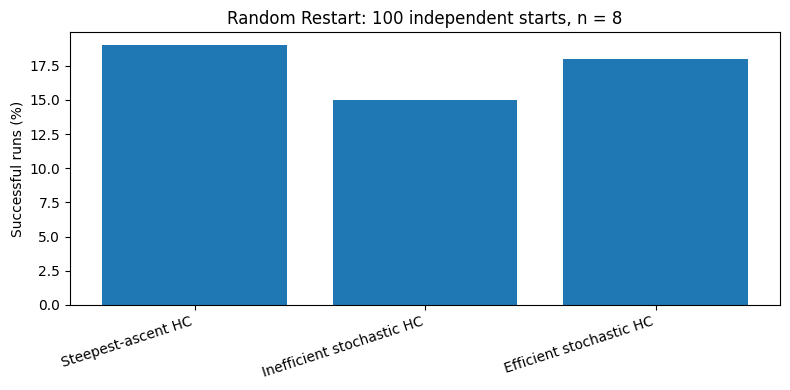

Steepest-ascent HC: best h=0; best board=[3, 6, 2, 7, 1, 4, 0, 5]
Inefficient stochastic HC: best h=0; best board=[2, 4, 7, 3, 0, 6, 1, 5]
Efficient stochastic HC: best h=0; best board=[3, 7, 0, 2, 5, 1, 6, 4]


In [8]:
# Task 4: Random Restart for all three Hill Climbing variants
# For fair accounting, each method is run from 100 independently generated initial boards.
# The function keeps the best board and reports the number of restarts that reached h=0.

def random_restart_search(algorithm, n, max_restarts=100, **kwargs):
    start_time = time.perf_counter()
    runs = []
    best_result = None
    for _ in range(max_restarts):
        result = algorithm(random_board(n), **kwargs)
        runs.append(result)
        if best_result is None or result["conflicts"] < best_result["conflicts"]:
            best_result = result
        # Continue all requested restarts so that success rates are measurable.
    successes = sum(int(r["success"]) for r in runs)
    return {
        "algorithm": getattr(algorithm, "__name__", str(algorithm)),
        "n": n,
        "restarts": max_restarts,
        "successes": successes,
        "success_rate": 100.0 * successes / max_restarts,
        "best_result": best_result,
        "avg_runtime": float(np.mean([r["runtime"] for r in runs])),
        "total_runtime": float(time.perf_counter() - start_time),
        "avg_evaluations": float(np.mean([r["evaluations"] for r in runs])),
        "runs": runs,
    }


np.random.seed(404)
_restart_algorithms = [
    ("Steepest-ascent HC", steepest_hill_climbing),
    ("Inefficient stochastic HC", inefficient_stochastic_hill_climbing),
    ("Efficient stochastic HC", efficient_stochastic_hill_climbing),
]
_restart_results = []
_restart_rows = []
for _label, _algorithm in _restart_algorithms:
    _summary = random_restart_search(_algorithm, n=8, max_restarts=100)
    _restart_results.append((_label, _summary))
    _restart_rows.append({
        "Algorithm": _label,
        "Restarts": _summary["restarts"],
        "Successful runs": _summary["successes"],
        "Success rate (%)": _summary["success_rate"],
        "Best h": _summary["best_result"]["conflicts"],
        "Avg. objective evaluations/run": _summary["avg_evaluations"],
        "Total time (s)": _summary["total_runtime"],
    })

import pandas as pd
display(pd.DataFrame(_restart_rows).round(4))
plt.figure(figsize=(8, 4))
plt.bar([r["Algorithm"] for r in _restart_rows], [r["Success rate (%)"] for r in _restart_rows])
plt.ylabel("Successful runs (%)")
plt.title("Random Restart: 100 independent starts, n = 8")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

for _label, _summary in _restart_results:
    print(f"{_label}: best h={_summary['best_result']['conflicts']}; "
          f"best board={_summary['best_result']['board'].tolist()}")

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

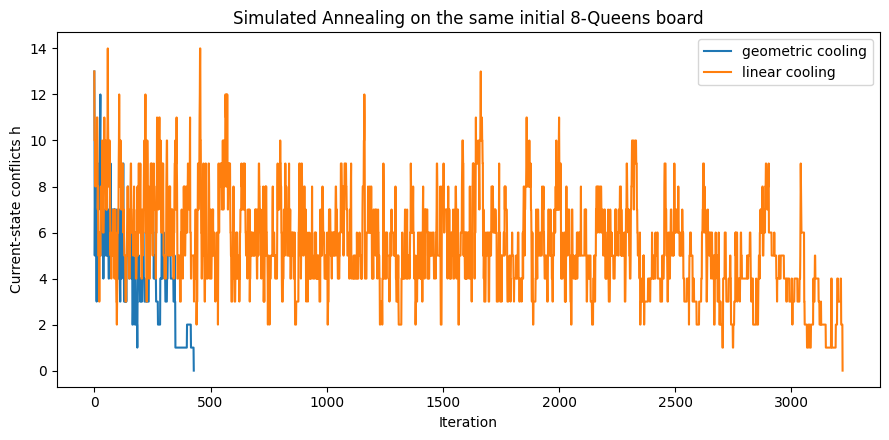

geometric: best h=0, current h=0, iterations=428, evaluations=429, time=0.005596s, status=solution found
linear: best h=0, current h=0, iterations=3220, evaluations=3221, time=0.039527s, status=solution found


**Schedule discussion.** Geometric cooling multiplies the temperature by a fixed factor each iteration, so exploration fades quickly and the run is usually shorter. Linear cooling lowers temperature steadily over a fixed horizon and can preserve exploration longer. A trace can rise because a worse state may be accepted early; its best-so-far value never increases. Results depend on the starting board and random seed, so schedule quality should be judged over repeated trials rather than one run.

In [9]:
# Task 5: Simulated Annealing
# A random neighbor is always considered. Improvements are accepted; worse states are
# accepted with probability exp(-delta / temperature). Two cooling schedules are supported.

def simulated_annealing(board, schedule="geometric", initial_temp=3.0,
                        cooling_rate=0.995, min_temp=0.01, max_iterations=4000):
    if schedule not in {"geometric", "linear"}:
        raise ValueError("schedule must be 'geometric' or 'linear'")

    start_time = time.perf_counter()
    current = np.asarray(board, dtype=int).copy()
    current_value = int(conflicts(current))
    best_board = current.copy()
    best_value = current_value
    evaluations = 1
    accepted_moves = 0
    trace = [current_value]
    best_history = [best_value]
    reason = "maximum iterations reached"

    for iteration in range(max_iterations):
        if current_value == 0:
            reason = "solution found"
            break

        if schedule == "geometric":
            temperature = initial_temp * (cooling_rate ** iteration)
            if temperature < min_temp:
                reason = "temperature below minimum"
                break
        else:
            # Linear schedule cools from initial_temp to approximately zero in max_iterations.
            temperature = initial_temp * (1.0 - iteration / max_iterations)
            if temperature <= 0:
                reason = "temperature reached zero"
                break

        candidate = _make_random_neighbor(current, "standard")
        candidate_value = int(conflicts(candidate))
        evaluations += 1
        delta = candidate_value - current_value

        if delta <= 0 or np.random.random() < math.exp(-delta / temperature):
            current = candidate
            current_value = candidate_value
            accepted_moves += 1

        if current_value < best_value:
            best_value = current_value
            best_board = current.copy()
        trace.append(current_value)
        best_history.append(best_value)

    if best_value == 0:
        reason = "solution found"
    result = _pack_result(best_board, best_value, accepted_moves, evaluations,
                          best_history, trace, start_time, reason,
                          iterations=len(trace) - 1)
    result["current_conflicts"] = int(current_value)
    result["schedule"] = schedule
    return result


_initial_sa_board = np.array(random_board(8), dtype=int)
_sa_results = {}
for _seed, _schedule in enumerate(("geometric", "linear"), start=1):
    np.random.seed(5100 + _seed)
    _sa_results[_schedule] = simulated_annealing(_initial_sa_board.copy(), schedule=_schedule)

plt.figure(figsize=(9, 4.5))
for _schedule, _result in _sa_results.items():
    plt.plot(_result["trace"], label=f"{_schedule} cooling")
plt.xlabel("Iteration")
plt.ylabel("Current-state conflicts h")
plt.title("Simulated Annealing on the same initial 8-Queens board")
plt.legend()
plt.tight_layout()
plt.show()

for _schedule, _result in _sa_results.items():
    print(f"{_schedule}: best h={_result['conflicts']}, current h={_result['current_conflicts']}, "
          f"iterations={_result['iterations']}, evaluations={_result['evaluations']}, "
          f"time={_result['runtime']:.6f}s, status={_result['reason']}")

display(Markdown(
    "**Schedule discussion.** Geometric cooling multiplies the temperature by a fixed factor each iteration, "
    "so exploration fades quickly and the run is usually shorter. Linear cooling lowers temperature steadily "
    "over a fixed horizon and can preserve exploration longer. A trace can rise because a worse state may be "
    "accepted early; its best-so-far value never increases. Results depend on the starting board and random seed, "
    "so schedule quality should be judged over repeated trials rather than one run."
))

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

,Algorithm,Board size,Avg. run time (s),Avg. conflicts (best h),Optimal runs (%),Avg. steps,Avg. objective evaluations
0,Steepest asc. HC,4,0.000171,0.68,34.0,1.51,27.0
1,Ineff. Stochastic HC,4,0.000209,0.90,27.0,1.93,32.9
2,Efficient Stochastic HC,4,0.000698,0.97,22.0,1.90,78.2
3,Simulated Annealing,4,0.000900,0.00,100.0,67.06,90.6
4,Steepest asc. HC,8,0.001891,1.23,13.0,3.24,231.2
5,Ineff. Stochastic HC,8,0.002539,1.32,14.0,4.86,321.3
6,Efficient Stochastic HC,8,0.006271,1.33,16.0,4.98,472.1
7,Simulated Annealing,8,0.009687,0.32,68.0,238.70,798.9


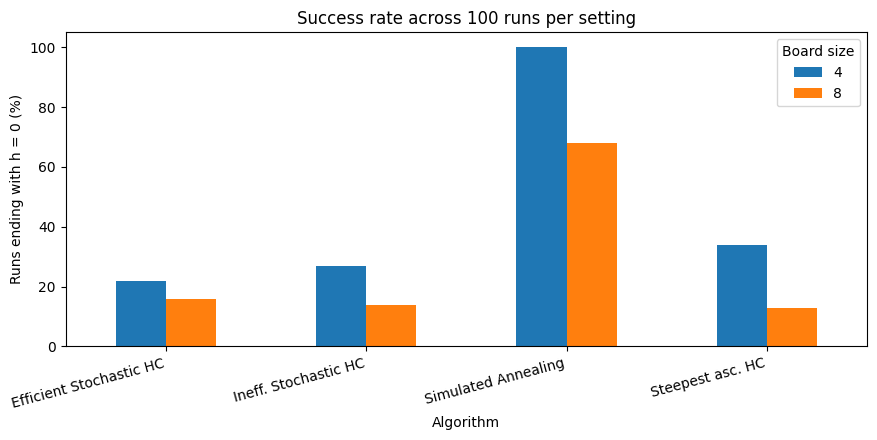

Experimental setup: 100 starts per algorithm for each n in {4, 8}; same start board within each trial; separate fixed seeds for algorithm randomness. 'Avg. conflicts' uses the returned best h for simulated annealing.


In [10]:
# Task 6: Controlled comparison (100 independent starts per algorithm and board size)
# The same initial board is passed to all algorithms in each trial. Each stochastic run gets
# a reproducible, separate random seed. Average runtime is measured inside each search routine.

_comparison_algorithms = [
    ("Steepest asc. HC", lambda b: steepest_hill_climbing(b)),
    ("Ineff. Stochastic HC", lambda b: inefficient_stochastic_hill_climbing(b)),
    ("Efficient Stochastic HC", lambda b: efficient_stochastic_hill_climbing(b)),
    ("Simulated Annealing", lambda b: simulated_annealing(b, schedule="geometric", max_iterations=4000)),
]
_comparison_rng = np.random.default_rng(20261018)
_comparison_rows = []
_comparison_records = {}
for _n in (4, 8):
    for _name, _run_algorithm in _comparison_algorithms:
        _runs = []
        for _trial in range(100):
            _start = _comparison_rng.integers(0, _n, size=_n)
            _algorithm_index = [x[0] for x in _comparison_algorithms].index(_name)
            np.random.seed(200000 + _n * 10000 + _trial * 20 + _algorithm_index)
            _runs.append(_run_algorithm(_start.copy()))
        comparison_key = (_n, _name)
        _comparison_records[comparison_key] = _runs
        _comparison_rows.append({
            "Algorithm": _name,
            "Board size": _n,
            "Avg. run time (s)": np.mean([r["runtime"] for r in _runs]),
            "Avg. conflicts (best h)": np.mean([r["conflicts"] for r in _runs]),
            "Optimal runs (%)": 100.0 * np.mean([r["success"] for r in _runs]),
            "Avg. steps": np.mean([r["steps"] for r in _runs]),
            "Avg. objective evaluations": np.mean([r["evaluations"] for r in _runs]),
        })

_comparison_df = pd.DataFrame(_comparison_rows)
display(_comparison_df.round({
    "Avg. run time (s)": 6,
    "Avg. conflicts (best h)": 3,
    "Optimal runs (%)": 1,
    "Avg. steps": 2,
    "Avg. objective evaluations": 1,
}))

_success_pivot = _comparison_df.pivot(index="Algorithm", columns="Board size", values="Optimal runs (%)")
_success_pivot.plot(kind="bar", figsize=(9, 4.5))
plt.ylabel("Runs ending with h = 0 (%)")
plt.title("Success rate across 100 runs per setting")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

print("Experimental setup: 100 starts per algorithm for each n in {4, 8}; same start board within each trial; "
      "separate fixed seeds for algorithm randomness. 'Avg. conflicts' uses the returned best h for simulated annealing.")

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

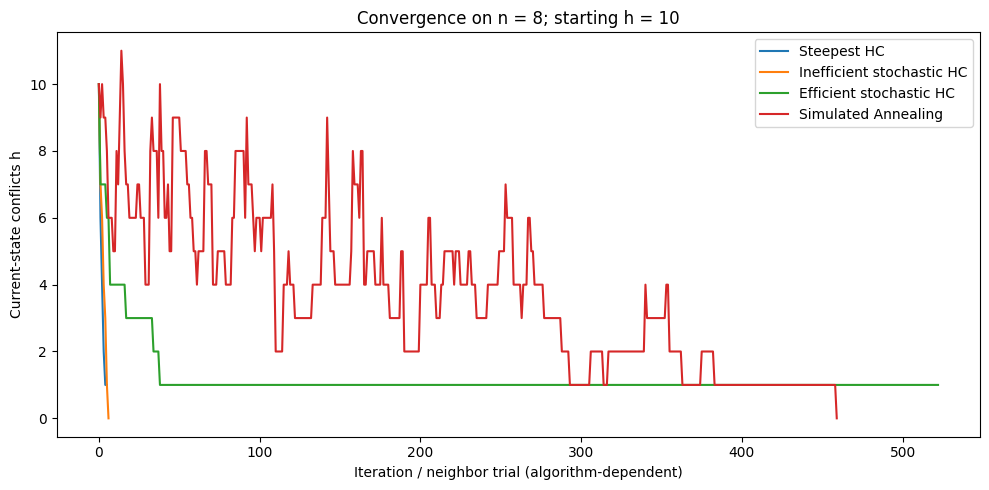

**Observed run.**

- **Steepest HC:** best h = 1, evaluations = 281, iterations/trials = 5.
- **Inefficient stochastic HC:** best h = 0, evaluations = 337, iterations/trials = 6.
- **Efficient stochastic HC:** best h = 1, evaluations = 523, iterations/trials = 522.
- **Simulated Annealing:** best h = 0, evaluations = 460, iterations/trials = 459.

**Interpretation.** Steepest-ascent makes the best available improvement after checking every neighbor, so each iteration is expensive but the objective decreases steadily. Inefficient stochastic HC also checks every neighbor but chooses randomly among improvements, which can take a less direct route. Efficient stochastic HC evaluates only one neighbor per trial, so the plot may contain long plateaus while it samples unsuccessful moves near a local optimum. Simulated annealing can temporarily move to a worse state, but this may help it leave a local optimum; the temperature schedule controls how long that exploration lasts. This is one representative run, not a guarantee of average behavior.

In [11]:
# Algorithm convergence on a representative n=8 run
# Steepest and inefficient stochastic search scan a complete neighborhood per iteration;
# efficient stochastic samples one move per iteration; simulated annealing may accept worse states.

_convergence_initial = np.array(np.random.default_rng(8128).integers(0, 8, size=8), dtype=int)
_convergence_methods = [
    ("Steepest HC", steepest_hill_climbing),
    ("Inefficient stochastic HC", inefficient_stochastic_hill_climbing),
    ("Efficient stochastic HC", efficient_stochastic_hill_climbing),
]
_convergence_results = {}
for _idx, (_label, _method) in enumerate(_convergence_methods):
    np.random.seed(8100 + _idx)
    _convergence_results[_label] = _method(_convergence_initial.copy())
np.random.seed(8199)
_convergence_results["Simulated Annealing"] = simulated_annealing(
    _convergence_initial.copy(), schedule="geometric", max_iterations=4000
)

plt.figure(figsize=(10, 5))
for _label, _result in _convergence_results.items():
    _values = _result["trace"][:2000]
    plt.plot(range(len(_values)), _values, label=_label)
plt.xlabel("Iteration / neighbor trial (algorithm-dependent)")
plt.ylabel("Current-state conflicts h")
plt.title(f"Convergence on n = 8; starting h = {conflicts(_convergence_initial)}")
plt.legend()
plt.tight_layout()
plt.show()

_convergence_summary = "\n".join(
    f"- **{name}:** best h = {result['conflicts']}, evaluations = {result['evaluations']}, "
    f"iterations/trials = {result['iterations']}."
    for name, result in _convergence_results.items()
)
display(Markdown(
    "**Observed run.**\n\n" + _convergence_summary +
    "\n\n**Interpretation.** Steepest-ascent makes the best available improvement after checking every neighbor, "
    "so each iteration is expensive but the objective decreases steadily. Inefficient stochastic HC also checks "
    "every neighbor but chooses randomly among improvements, which can take a less direct route. Efficient stochastic "
    "HC evaluates only one neighbor per trial, so the plot may contain long plateaus while it samples unsuccessful "
    "moves near a local optimum. Simulated annealing can temporarily move to a worse state, but this may help it leave "
    "a local optimum; the temperature schedule controls how long that exploration lasts. This is one representative run, "
    "not a guarantee of average behavior."
))

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

,Algorithm,n,Mean runtime (s),Mean best h,Runs
0,Steepest-ascent HC,4,0.000147,1.0,5
1,Simulated Annealing (geometric),4,0.000573,0.0,5
2,Steepest-ascent HC,8,0.001652,1.8,5
3,Simulated Annealing (geometric),8,0.010482,0.4,5
4,Steepest-ascent HC,12,0.006451,2.4,5
5,Simulated Annealing (geometric),12,0.017460,0.8,5
6,Steepest-ascent HC,16,0.023838,1.6,5
7,Simulated Annealing (geometric),16,0.017895,1.8,5
8,Steepest-ascent HC,20,0.049208,2.4,5
9,Simulated Annealing (geometric),20,0.021183,2.2,5


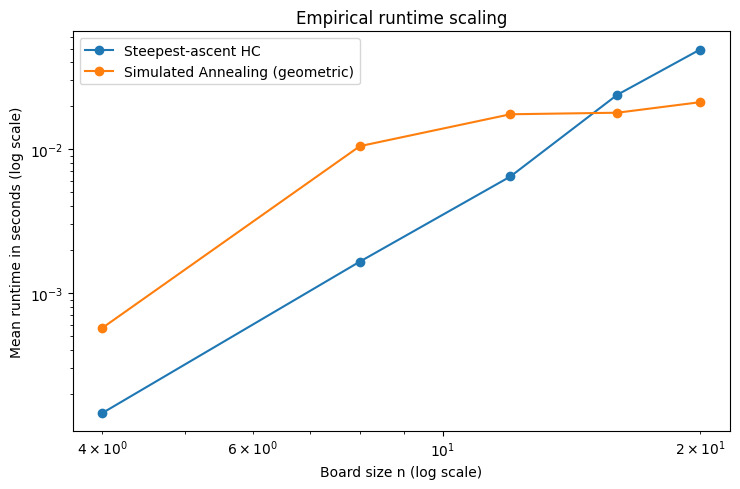

Steepest-ascent HC: fitted empirical trend approximately O(n^3.63) over the tested sizes.
Simulated Annealing (geometric): fitted empirical trend approximately O(n^2.19) over the tested sizes.


**Complexity discussion.** The fitted exponents are empirical descriptions of this implementation and these five board sizes, not formal worst-case proofs. Steepest-ascent evaluates all n(n-1) one-queen moves at each step; one conflict evaluation costs O(n), and the number of accepted improvements depends on the starting state. A loose worst-case upper bound from at most O(n²) strict objective decreases is O(n⁵). Geometric simulated annealing uses a bounded cooling schedule (roughly a fixed number of iterations here), with O(n) work per conflict evaluation, so it often scales more gently in runtime. However, a fast annealing run can finish without finding h=0; runtime alone does not measure solution reliability. Small-n timings are also sensitive to interpreter and machine overhead.

In [12]:
# Problem-size scalability: log-log runtime plot for n = 4, 8, 12, 16, 20
# Use five starting boards per setting and report the empirical power-law slope of mean runtime.

_scalability_ns = np.array([4, 8, 12, 16, 20])
_scalability_methods = [
    ("Steepest-ascent HC", lambda b: steepest_hill_climbing(b)),
    ("Simulated Annealing (geometric)", lambda b: simulated_annealing(b, schedule="geometric", max_iterations=4000)),
]
_scalability_rng = np.random.default_rng(280028)
_scalability_times = {name: [] for name, _ in _scalability_methods}
_scalability_rows = []
for _n in _scalability_ns:
    for _method_index, (_name, _method) in enumerate(_scalability_methods):
        _times = []
        _conflicts = []
        for _trial in range(5):
            _start = _scalability_rng.integers(0, int(_n), size=int(_n))
            np.random.seed(280000 + int(_n) * 100 + _trial * 10 + _method_index)
            _result = _method(_start.copy())
            _times.append(_result["runtime"])
            _conflicts.append(_result["conflicts"])
        _mean_time = float(np.mean(_times))
        _scalability_times[_name].append(_mean_time)
        _scalability_rows.append({
            "Algorithm": _name,
            "n": int(_n),
            "Mean runtime (s)": _mean_time,
            "Mean best h": float(np.mean(_conflicts)),
            "Runs": 5,
        })

_scalability_df = pd.DataFrame(_scalability_rows)
display(_scalability_df.round({"Mean runtime (s)": 6, "Mean best h": 3}))

plt.figure(figsize=(7.5, 5))
for _name, _times in _scalability_times.items():
    plt.loglog(_scalability_ns, np.maximum(_times, 1e-9), marker="o", label=_name)
plt.xlabel("Board size n (log scale)")
plt.ylabel("Mean runtime in seconds (log scale)")
plt.title("Empirical runtime scaling")
plt.legend()
plt.tight_layout()
plt.show()

_scalability_slopes = {}
for _name, _times in _scalability_times.items():
    _slope, _intercept = np.polyfit(np.log(_scalability_ns), np.log(np.maximum(_times, 1e-9)), 1)
    _scalability_slopes[_name] = float(_slope)
    print(f"{_name}: fitted empirical trend approximately O(n^{_slope:.2f}) over the tested sizes.")

display(Markdown(
    "**Complexity discussion.** The fitted exponents are empirical descriptions of this implementation and these "
    "five board sizes, not formal worst-case proofs. Steepest-ascent evaluates all n(n-1) one-queen moves at each "
    "step; one conflict evaluation costs O(n), and the number of accepted improvements depends on the starting state. "
    "A loose worst-case upper bound from at most O(n²) strict objective decreases is O(n⁵). Geometric simulated annealing "
    "uses a bounded cooling schedule (roughly a fixed number of iterations here), with O(n) work per conflict evaluation, "
    "so it often scales more gently in runtime. However, a fast annealing run can finish without finding h=0; runtime "
    "alone does not measure solution reliability. Small-n timings are also sensitive to interpreter and machine overhead."
))

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

,n,Move operator,Success rate (%),Mean final h,Median final h,Mean evals/run,Mean time to solution (s),Successful runs
0,8,Standard one-queen,9.0,1.42,1.0,210.2,0.001418,9
1,8,Single-step,0.0,3.45,3.0,186.6,NaN,0
2,8,Column swap,0.0,4.40,4.0,188.4,NaN,0
3,8,Dual-queen,3.0,1.58,2.0,248.4,0.002383,3
4,8,Adaptive,14.0,1.33,1.0,171.7,0.001586,14
5,12,Standard one-queen,8.0,1.64,2.0,530.2,0.002771,8
6,12,Single-step,0.0,5.54,6.0,440.7,NaN,0
7,12,Column swap,0.0,6.50,6.0,469.2,NaN,0
8,12,Dual-queen,0.0,2.17,2.0,644.5,NaN,0
9,12,Adaptive,4.0,1.84,2.0,441.7,0.002547,4


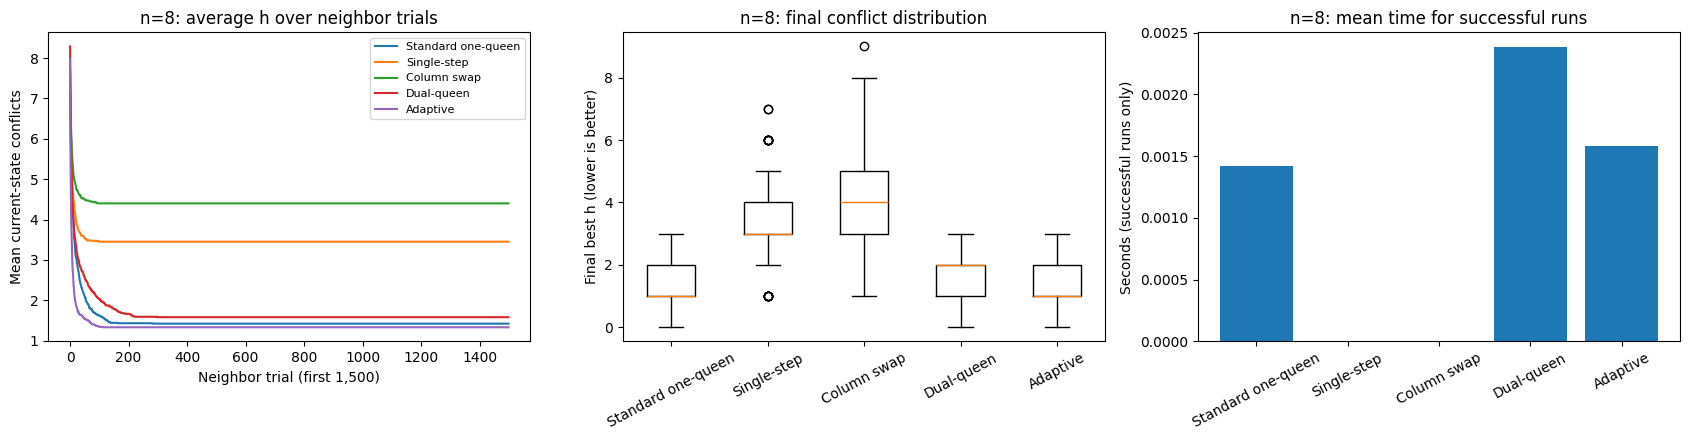

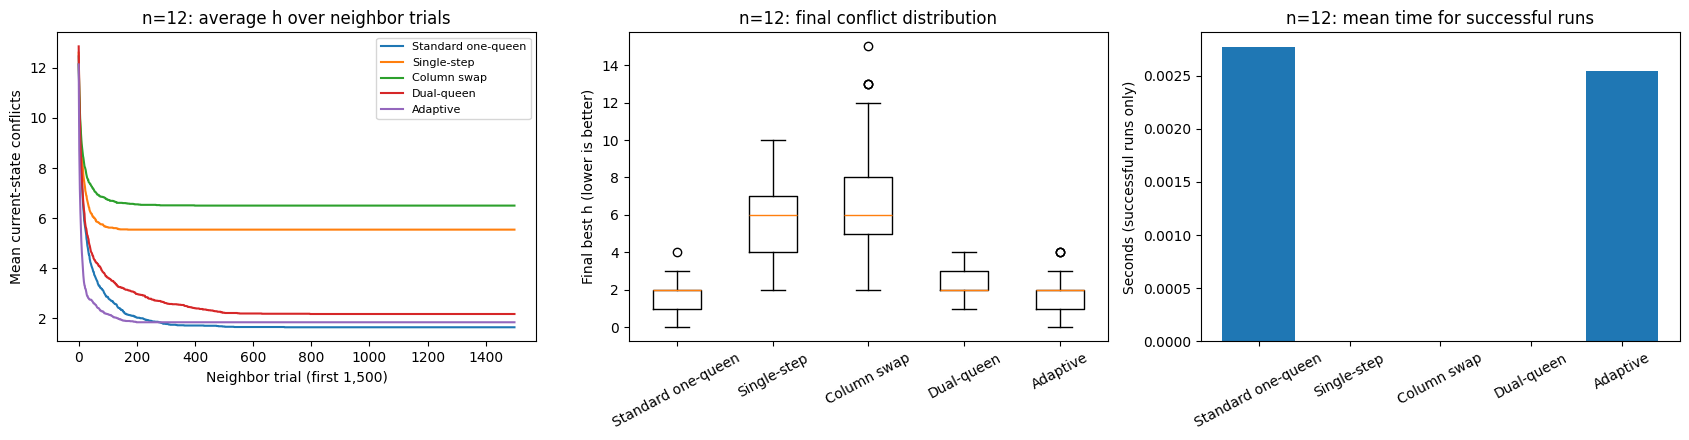

**Discussion for n=8.** By mean final conflicts, the strongest result in these trials was **Adaptive** (mean h=1.330); by success rate, the highest was **Adaptive** (14.0%). These rankings can differ because a low average conflict count is not the same as a high percentage of exact solutions. Single-step moves explore a narrower neighborhood and can stall; column swaps preserve the multiset of row values; dual-queen moves can change two assignments at once and may cross a plateau but can also disrupt a good partial state; the adaptive operator directs moves toward queens involved in many conflicts. The best choice is therefore empirical and depends on n, the starting boards, the stopping budget, and whether the priority is success rate, final h, or time.

**Discussion for n=12.** By mean final conflicts, the strongest result in these trials was **Standard one-queen** (mean h=1.640); by success rate, the highest was **Standard one-queen** (8.0%). These rankings can differ because a low average conflict count is not the same as a high percentage of exact solutions. Single-step moves explore a narrower neighborhood and can stall; column swaps preserve the multiset of row values; dual-queen moves can change two assignments at once and may cross a plateau but can also disrupt a good partial state; the adaptive operator directs moves toward queens involved in many conflicts. The best choice is therefore empirical and depends on n, the starting boards, the stopping budget, and whether the priority is success rate, final h, or time.

Advanced-task setup: 100 starts per operator for n=8 and n=12; fixed stagnation budget within each board size; failed runs are included in final-conflict distributions, but excluded from mean time-to-solution.


In [13]:
# Advanced task: compare the four requested local-move operators with the original operator as a baseline.
# Every operator receives 100 starts for n=8 and n=12. A fixed per-trial stagnation budget
# is used across operators so the comparison does not silently give one operator far more attempts.

_advanced_operators = [
    ("Standard one-queen", "standard"),
    ("Single-step", "single_step"),
    ("Column swap", "column_swap"),
    ("Dual-queen", "dual_queen"),
    ("Adaptive", "adaptive"),
]
_advanced_rng = np.random.default_rng(303030)
_advanced_data = {}
_advanced_rows = []
_advanced_repeats = 100

for _n in (8, 12):
    _advanced_data[_n] = {}
    # Same stopping budget within a given n for each operator.
    _stagnation_budget = max(80, 3 * _n * (_n - 1))
    for _op_index, (_label, _operator) in enumerate(_advanced_operators):
        _summaries = []
        for _trial in range(_advanced_repeats):
            _start = _advanced_rng.integers(0, _n, size=_n)
            np.random.seed(300000 + _n * 10000 + _op_index * 1000 + _trial)
            _result = efficient_stochastic_hill_climbing(
                _start, move_operator=_operator, stagnation_limit=_stagnation_budget
            )
            # Keep only the trace prefix needed for plots to limit notebook memory use.
            _summaries.append({
                "conflicts": _result["conflicts"],
                "success": _result["success"],
                "runtime": _result["runtime"],
                "steps": _result["steps"],
                "evaluations": _result["evaluations"],
                "history": _result["history"],
                "trace": _result["trace"][:1500],
            })
        _advanced_data[_n][_label] = _summaries
        _successful_times = [r["runtime"] for r in _summaries if r["success"]]
        _advanced_rows.append({
            "n": _n,
            "Move operator": _label,
            "Success rate (%)": 100.0 * np.mean([r["success"] for r in _summaries]),
            "Mean final h": np.mean([r["conflicts"] for r in _summaries]),
            "Median final h": np.median([r["conflicts"] for r in _summaries]),
            "Mean evals/run": np.mean([r["evaluations"] for r in _summaries]),
            "Mean time to solution (s)": np.mean(_successful_times) if _successful_times else np.nan,
            "Successful runs": len(_successful_times),
        })

_advanced_df = pd.DataFrame(_advanced_rows)
display(_advanced_df.round({
    "Success rate (%)": 1,
    "Mean final h": 3,
    "Median final h": 1,
    "Mean evals/run": 1,
    "Mean time to solution (s)": 6,
}))


def _mean_padded_trace(results, max_len=1500):
    traces = []
    for result in results:
        values = list(result["trace"][:max_len])
        if not values:
            values = [result["conflicts"]]
        if len(values) < max_len:
            values.extend([values[-1]] * (max_len - len(values)))
        traces.append(values)
    return np.mean(np.asarray(traces, dtype=float), axis=0)


for _n in (8, 12):
    _fig, _axes = plt.subplots(1, 3, figsize=(17, 4.5))

    # Plot 1: average state quality by neighbor-trial count (plateaus are retained).
    for _label, _operator in _advanced_operators:
        _mean_trace = _mean_padded_trace(_advanced_data[_n][_label])
        _axes[0].plot(_mean_trace, label=_label)
    _axes[0].set_title(f"n={_n}: average h over neighbor trials")
    _axes[0].set_xlabel("Neighbor trial (first 1,500)")
    _axes[0].set_ylabel("Mean current-state conflicts")
    _axes[0].legend(fontsize=8)

    # Plot 2: distribution of final best objective values over 100 runs.
    _box_data = [[r["conflicts"] for r in _advanced_data[_n][label]]
                 for label, _operator in _advanced_operators]
    _axes[1].boxplot(_box_data, tick_labels=[label for label, _operator in _advanced_operators])
    _axes[1].set_title(f"n={_n}: final conflict distribution")
    _axes[1].set_ylabel("Final best h (lower is better)")
    _axes[1].tick_params(axis="x", labelrotation=28)

    # Plot 3: mean time to solution, calculated only from successful runs.
    _time_values = []
    for _label, _operator in _advanced_operators:
        _ok_times = [r["runtime"] for r in _advanced_data[_n][_label] if r["success"]]
        _time_values.append(float(np.mean(_ok_times)) if _ok_times else np.nan)
    _axes[2].bar([label for label, _operator in _advanced_operators], _time_values)
    _axes[2].set_title(f"n={_n}: mean time for successful runs")
    _axes[2].set_ylabel("Seconds (successful runs only)")
    _axes[2].tick_params(axis="x", labelrotation=28)

    _fig.tight_layout()
    plt.show()

for _n in (8, 12):
    _part = _advanced_df[_advanced_df["n"] == _n]
    _best_quality = _part.sort_values("Mean final h").iloc[0]
    _best_success = _part.sort_values("Success rate (%)", ascending=False).iloc[0]
    display(Markdown(
        f"**Discussion for n={_n}.** By mean final conflicts, the strongest result in these trials was "
        f"**{_best_quality['Move operator']}** (mean h={_best_quality['Mean final h']:.3f}); by success rate, "
        f"the highest was **{_best_success['Move operator']}** ({_best_success['Success rate (%)']:.1f}%). "
        "These rankings can differ because a low average conflict count is not the same as a high percentage of exact solutions. "
        "Single-step moves explore a narrower neighborhood and can stall; column swaps preserve the multiset of row values; "
        "dual-queen moves can change two assignments at once and may cross a plateau but can also disrupt a good partial state; "
        "the adaptive operator directs moves toward queens involved in many conflicts. The best choice is therefore empirical "
        "and depends on n, the starting boards, the stopping budget, and whether the priority is success rate, final h, or time."
    ))

print("Advanced-task setup: 100 starts per operator for n=8 and n=12; fixed stagnation budget within each board size; "
      "failed runs are included in final-conflict distributions, but excluded from mean time-to-solution.")

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# Code and description go here